# Partie 1 : modèles entraînés de zéro

On construit deux CNN simples et on les entraîne sur nos images en 128×128 :

- 1.2 CNN-Plain, un CNN classique de 6 couches de convolution, avec le calcul des dimensions à la main ;
- 1.3 CNN-Res, la même profondeur avec des connexions résiduelles et un GAP ;
- 1.4 l'effet du learning rate ;
- 1.5 la norme du gradient dans chaque couche ;
- 1.6 le tableau comparatif.

La partie 1.1 (exploration et découpage) est dans le notebook 00.

- On ajoute le dossier du projet au chemin de Python pour pouvoir importer notre code (`src/`).
- `config` contient les chemins, la maladie M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard, pour retrouver les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée.

In [23]:
import sys
from pathlib import Path

#dossier du projet pour pouvoir importer src/
sys.path.insert(0, str(Path.cwd().parent))

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- On relit le découpage (`splits.csv`) et la normalisation calculée sur le train dans le notebook 00.
- `clf_loaders` prépare les images en 128×128. Sur le train seulement, on les retourne et on les tourne de 90° au hasard, pour avoir plus de variété.
- La perte est l'entropie croisée pondérée par classe, à cause du déséquilibre.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchinfo import summary

from src import data as D
from src.models import CNNPlain, CNNRes
from src.train import fit, load_best
from src.metrics import (predict, clf_report, plot_confusion, plot_histories, count_params, model_size_mb, upsert_summary, savefig)

df = D.load_splits()
norm = D.norm_stats("scratch")
loaders = D.clf_loaders(df, D.CLASSES, C.SCRATCH_SIZE, norm, batch_size=64)
for nom, l in loaders.items():
    print(nom, len(l.dataset), "images")

poids = D.class_weights(loaders["train"].dataset.labels, len(D.CLASSES)).to(C.DEVICE)
criterion = nn.CrossEntropyLoss(weight=poids)
NOMS = [D.short(c) for c in D.CLASSES]

train 12711 images
val 2724 images
test 2725 images


## 1.2 CNN-Plain

Le réseau a 3 étages de 2 blocs Conv-BN-ReLU, avec un MaxPool 2×2 après chaque étage. Ensuite viennent Flatten, une couche Dense de 32 neurones (avec BN et ReLU), un Dropout de 0,3 et la couche de sortie à 10 neurones.

### Calcul des dimensions à la main

On reprend les notations du cours : une image ou une carte a pour dimensions $W \times H \times D$ (largeur, hauteur, profondeur).

- Convolution, avec $K$ filtres de taille $F$, un pas $S$ et un padding $P$ : $W_c = \frac{W - F + 2P}{S} + 1$, $\quad H_c = \frac{H - F + 2P}{S} + 1$, $\quad D_c = K$
- Pooling, avec une fenêtre $F$ et un pas $S$ : $W_p = \frac{W - F}{S} + 1$, $\quad H_p = \frac{H - F}{S} + 1$, $\quad D_p = D$
- Nombre de poids d'une convolution : $F \times F \times D \times K$ (plus $K$ biais)

Avec la règle du cours $P = \frac{F - 1}{2}$ et $S = 1$, donc $F = 3$ et $P = 1$, on a $W_c = \frac{W - 3 + 2}{1} + 1 = W$ : la convolution garde la taille. Seul le pooling ($F = 2$, $S = 2$) la divise par 2.

Nos convolutions n'ont pas de biais, parce que la BatchNorm qui suit en a déjà un ($\beta$). Chaque BatchNorm ajoute $2K$ paramètres ($\gamma$ et $\beta$). Les images sont carrées, donc $H = W$ partout.

| Couche | Calcul | Sortie $W \times H \times D$ | Paramètres |
|---|---|---|---|
| Entrée | | 128 × 128 × 3 | 0 |
| Conv1 (K=32, F=3, S=1, P=1) + BN | $W_c$ = (128 − 3 + 2)/1 + 1 = 128, $D_c$ = 32 | 128 × 128 × 32 | 3×3×3×32 = 864, + 64 |
| Conv2 (K=32) + BN | 128 | 128 × 128 × 32 | 3×3×32×32 = 9 216, + 64 |
| MaxPool (F=2, S=2) | $W_p$ = (128 − 2)/2 + 1 = 64, $D_p$ = 32 | 64 × 64 × 32 | 0 |
| Conv3 (K=64) + BN | 64 | 64 × 64 × 64 | 3×3×32×64 = 18 432, + 128 |
| Conv4 (K=64) + BN | 64 | 64 × 64 × 64 | 3×3×64×64 = 36 864, + 128 |
| MaxPool (F=2, S=2) | (64 − 2)/2 + 1 = 32 | 32 × 32 × 64 | 0 |
| Conv5 (K=128) + BN | 32 | 32 × 32 × 128 | 3×3×64×128 = 73 728, + 256 |
| Conv6 (K=128) + BN | 32 | 32 × 32 × 128 | 3×3×128×128 = 147 456, + 256 |
| MaxPool (F=2, S=2) | (32 − 2)/2 + 1 = 16 | 16 × 16 × 128 | 0 |
| Flatten | 16 × 16 × 128 | 32 768 | 0 |
| Dense 32 | | 32 | 32 768 × 32 + 32 = 1 048 608 |
| BN + ReLU | | 32 | 2 × 32 = 64 |
| Dropout 0,3 | | 32 | 0 |
| Dense 10 (softmax dans la perte) | | 10 | 32 × 10 + 10 = 330 |
| **Total** | | | **1 336 458** |

`torchinfo` affiche les tailles dans l'ordre de PyTorch, $D \times H \times W$ (par exemple `[1, 32, 128, 128]`). Ce sont les mêmes nombres, rangés autrement.

### Pourquoi ces choix

Nous utilisons des noyaux 3×3, comme VGG : deux 3×3 à la suite couvrent la même zone qu'un 5×5, avec moins de poids (18 au lieu de 25) et une ReLU de plus. Le padding de 1 garde la taille dans chaque étage, et c'est le pooling qui la réduit (128, 64, 32, 16). On double le nombre de filtres (32, 64, 128) à chaque fois que la taille est divisée par 2 : les cartes deviennent plus petites mais plus nombreuses.

La couche Dense n'a que 32 neurones, parce qu'après le Flatten il y a 32 768 valeurs et que chaque neurone coûte autant de poids. Malgré ça, la tête pèse déjà 78 % du modèle. Le Dropout de 0,3 est placé dans cette tête, la partie qui sur-apprend le plus facilement.

Nous avons ajouté une BatchNorm après la couche Dense suite à un premier essai raté. Sans elle, 30 neurones sur 32 de cette couche étaient « morts » (leur ReLU sortait 0 pour toutes les images) et le modèle plafonnait à 46 % de F1. Comme la couche reçoit 32 768 valeurs d'un coup, les sommes sont très grandes, et l'optimiseur pousse vite les neurones là où la ReLU vaut 0. La BatchNorm recentre ces sommes, comme dans les blocs Conv-BN-ReLU.

- `torchinfo` affiche la taille de sortie et le nombre de paramètres de chaque couche. On retrouve bien le total calculé à la main : 1 336 458.

In [25]:
summary(CNNPlain(10), input_size=(1, 3, 128, 128), col_names=("output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
CNNPlain                                 [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 16, 16]          --
│    └─Sequential: 2-1                   [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-1                  [1, 32, 128, 128]         864
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         --
│    └─Sequential: 2-2                   [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-4                  [1, 32, 128, 128]         9,216
│    │    └─BatchNorm2d: 3-5             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-6                    [1, 32, 128, 128]         --
│    └─MaxPool2d: 2-3                    [1, 32, 64, 64]           --
│    └─Sequential: 2-4                   [1, 64, 64, 64]           --
│    │    └─Conv2d: 3-7                  [1, 64, 64, 64]           18,432
│    │ 

## 1.3 CNN-Res

On garde 6 convolutions 3×3, mais on les regroupe en 3 blocs résiduels (comme dans le TP2, exercice 7), chacun suivi d'un MaxPool. Dans un bloc résiduel, on ajoute l'entrée du bloc à sa sortie : $y = F(x) + x$, où $F$ = Conv-BN-ReLU-Conv-BN. Quand le nombre de canaux change, on ne peut pas additionner directement, donc on passe l'entrée dans une convolution 1×1 : $y = F(x) + W_s x$ (raccourci par projection).

À la place de Flatten + Dense, on utilise un Global Average Pooling (TP2, exercice 6) : chaque carte est remplacée par sa moyenne. La tête n'a alors plus que 256 × 10 + 10 = 2 570 paramètres.

Pour comparer à budget égal, il faut un nombre de paramètres proche de celui de CNN-Plain. Avec les mêmes largeurs (32, 64, 128), CNN-Res n'aurait que 0,3 M de paramètres, puisque le GAP supprime la grosse couche Dense. On passe donc à 64, 128 et 256 filtres :

| Bloc | Sortie après pool ($W \times H \times D$) | Paramètres (convolutions + raccourci 1×1 + BN) |
|---|---|---|
| Bloc 1 (3 → 64) | 64 × 64 × 64 | 1 728 + 36 864 + 192 + 384 = 39 168 |
| Bloc 2 (64 → 128) | 32 × 32 × 128 | 73 728 + 147 456 + 8 192 + 768 = 230 144 |
| Bloc 3 (128 → 256) | 16 × 16 × 256 | 294 912 + 589 824 + 32 768 + 1 536 = 919 040 |
| GAP + Dropout + Dense 10 | 10 | 2 570 |
| **Total** | | **1 190 922** |

On arrive à 1,19 M de paramètres pour CNN-Res contre 1,34 M pour CNN-Plain. La différence, c'est que CNN-Plain met l'essentiel de ses paramètres dans la couche Dense, alors que CNN-Res les met dans les convolutions.

- On vérifie le tableau de CNN-Res avec `torchinfo` : 1 190 922 paramètres.

In [26]:
summary(CNNRes(10), input_size=(1, 3, 128, 128), col_names=("output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
CNNRes                                   [1, 10]                   --
├─Sequential: 1-1                        [1, 256, 16, 16]          --
│    └─ResidualBlock: 2-1                [1, 64, 128, 128]         --
│    │    └─Conv2d: 3-1                  [1, 64, 128, 128]         1,728
│    │    └─BatchNorm2d: 3-2             [1, 64, 128, 128]         128
│    │    └─Conv2d: 3-3                  [1, 64, 128, 128]         36,864
│    │    └─BatchNorm2d: 3-4             [1, 64, 128, 128]         128
│    │    └─Sequential: 3-5              [1, 64, 128, 128]         320
│    └─MaxPool2d: 2-2                    [1, 64, 64, 64]           --
│    └─ResidualBlock: 2-3                [1, 128, 64, 64]          --
│    │    └─Conv2d: 3-6                  [1, 128, 64, 64]          73,728
│    │    └─BatchNorm2d: 3-7             [1, 128, 64, 64]          256
│    │    └─Conv2d: 3-8                  [1, 128, 64, 64]          147

### Entraînement

Les deux modèles ont exactement les mêmes réglages : Adam, learning rate de 0,001, batch de 64, 15 époques, perte pondérée. À chaque époque, on garde les poids si le F1 macro de validation est le meilleur obtenu jusque-là. On note aussi la norme du gradient de chaque convolution toutes les 20 itérations, pour la partie 1.5.

- `entrainer` met le modèle sur le GPU, crée l'optimiseur Adam et lance l'entraînement (`fit`).
- `fit` enregistre à chaque époque la perte et l'accuracy (train et validation), le F1 de validation et le temps. Les historiques vont dans `results/runs/`, les poids dans `results/ckpt/`.
- `set_seed(42)` avant chaque modèle : les deux partent de la même graine.
- Si l'entraînement est coupé, relancer la cellule le fait reprendre à la dernière époque enregistrée.

In [27]:
EPOCHS = C.ep(15)

def entrainer(nom, arch, model, lr, epochs, grad_every=None):
    model = model.to(C.DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    meta = {"arch": arch, "classes": D.CLASSES, "size": 128, "lr": lr, "epochs": epochs}
    historique = fit(model, loaders, epochs, optimizer, criterion, nom, meta, grad_every=grad_every)
    return model, historique

C.set_seed(42)                   # même initialisation pour les deux modèles
plain, h_plain = entrainer("cnn_plain", "cnn_plain", CNNPlain(10), 0.001, EPOCHS, grad_every=20)

C.set_seed(42)
res, h_res = entrainer("cnn_res", "cnn_res", CNNRes(10), 0.001, EPOCHS, grad_every=20)

Reprise depuis l'époque 15
Reprise depuis l'époque 15


- Courbes de perte et d'accuracy : pointillés pour le train, trait plein pour la validation. Si le train continue de s'améliorer pendant que la validation stagne ou recule, le modèle sur-apprend.

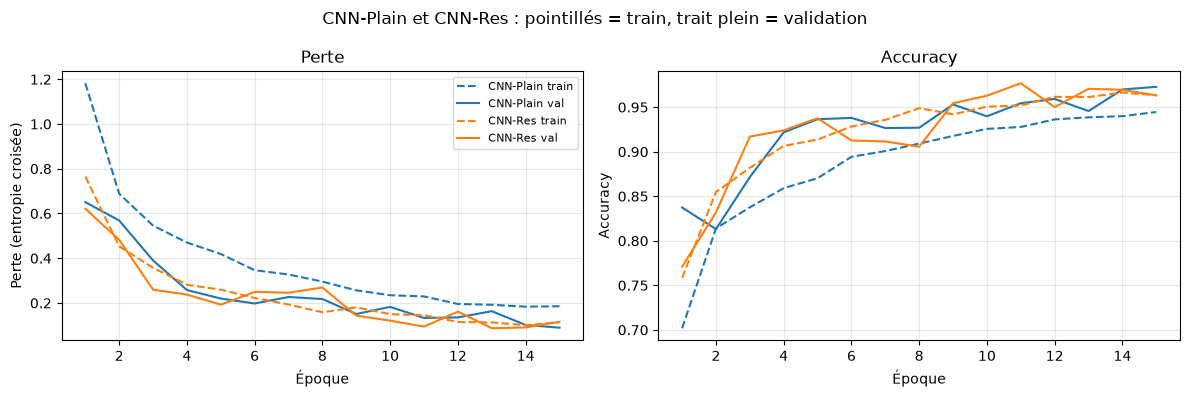

In [28]:
plot_histories({"CNN-Plain": h_plain, "CNN-Res": h_res}, path=C.FIG_DIR / "01_courbes_plain_res.png",
               title="CNN-Plain et CNN-Res : pointillés = train, trait plein = validation")

### Ce qu'on observe

Aucun des deux modèles ne sur-apprend en 15 époques : les pertes de train et de validation baissent ensemble et restent proches. L'accuracy de train est même un peu plus basse que celle de validation (0,94 contre 0,97 pour CNN-Plain à la fin). C'est normal : pendant l'entraînement, les images sont retournées ou tournées et le Dropout est actif, ce qui rend la tâche plus dure qu'en validation.

CNN-Res apprend plus vite au début (0,917 d'accuracy de validation dès l'époque 3, contre 0,87 pour CNN-Plain). À la fin, les deux sont presque au même niveau, avec un meilleur F1 de validation de 0,974 pour CNN-Res et 0,971 pour CNN-Plain.

Notre premier essai de CNN-Plain, sans BatchNorm après la couche Dense, ne dépassait pas 0,46 de F1, et l'accuracy de train (0,47) était plus basse que celle de validation (0,60). En regardant les sorties de la couche Dense, nous avons vu que 30 neurones sur 32 restaient toujours à 0. Le modèle n'arrivait donc pas à apprendre : ce n'était pas du sur-apprentissage, mais un problème d'optimisation. Ajouter une BatchNorm (64 paramètres de plus) a suffi.

## 1.4 Effet du learning rate

On reprend la grille du TP1 (exercice 5) : on entraîne CNN-Res avec 4 learning rates, 0,1, 0,01, 0,001 et 0,0001. Tout le reste ne change pas (Adam, 10 époques). On compare les courbes de validation, sans toucher au test.

- Une boucle sur les 4 learning rates. Chaque essai a son propre nom et ses propres fichiers.
- Chaque essai est ajouté au tableau récapitulatif (`summary.csv`) avec son F1 de validation.
- On superpose les courbes des 4 essais et on affiche le meilleur F1 de validation de chacun.

Reprise depuis l'époque 10
Reprise depuis l'époque 10
Reprise depuis l'époque 10
Reprise depuis l'époque 10


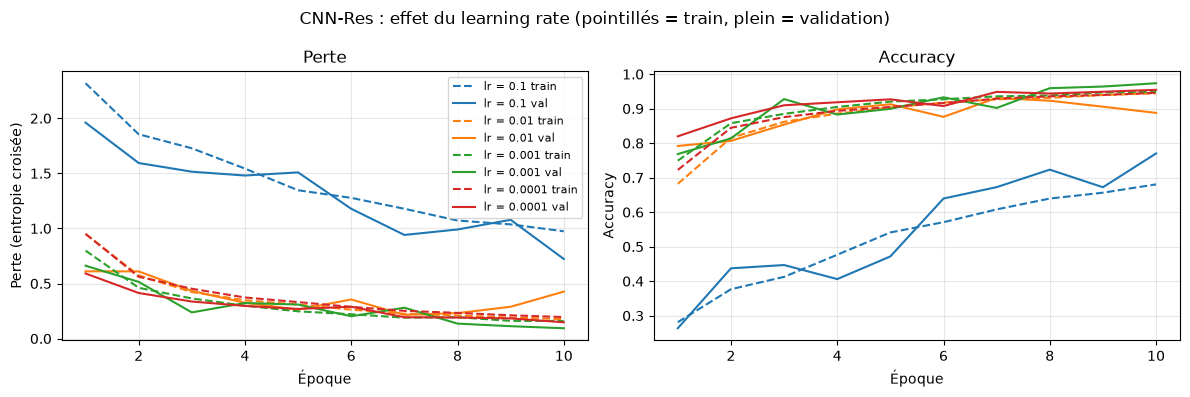

lr = 0.1 : meilleur F1 val = 0.7465 (époque 10 ), perte train finale = 0.9742
lr = 0.01 : meilleur F1 val = 0.9191 (époque 8 ), perte train finale = 0.1772
lr = 0.001 : meilleur F1 val = 0.9662 (époque 10 ), perte train finale = 0.1597
lr = 0.0001 : meilleur F1 val = 0.9524 (époque 10 ), perte train finale = 0.1955


In [29]:
historiques_lr = {}
for lr, texte in [(0.1, "0.1"), (0.01, "0.01"), (0.001, "0.001"), (0.0001, "0.0001")]:
    C.set_seed(42)
    _, h = entrainer("cnn_res_lr" + texte, "cnn_res", CNNRes(10), lr, C.ep(10))
    historiques_lr["lr = " + texte] = h
    upsert_summary({"experiment": "P1_CNN-Res_lr=" + texte, "partie": 1, "modele": "CNN-Res",
                    "hyperparametres": "Adam lr=" + texte + ", batch 64, 10 époques",
                    "temps_entrainement_s": round(h["train_time_s"].iloc[-1], 1), "val_f1": round(h["val_f1"].max(), 4)})

plot_histories(historiques_lr, path=C.FIG_DIR / "01_etude_lr.png",
               title="CNN-Res : effet du learning rate (pointillés = train, plein = validation)")

for nom in historiques_lr:
    h = historiques_lr[nom]
    meilleure_epoque = h["val_f1"].idxmax() + 1
    print(nom, ": meilleur F1 val =", round(h["val_f1"].max(), 4), "(époque", meilleure_epoque, "),",
          "perte train finale =", round(h["train_loss"].iloc[-1], 4))

### Ce qu'on observe

Avec 0,1, le pas est beaucoup trop grand et le modèle n'arrive pas à bien descendre. Après 10 époques, la perte de train est encore à 0,97 et l'accuracy de validation plafonne à 0,77 (F1 de 0,75), avec des remontées d'une époque à l'autre.

Avec 0,01, le modèle apprend vite mais la validation est instable. À la fin, la perte de validation remonte (0,43 à l'époque 10) alors que celle du train continue de baisser, et le F1 redescend de 0,919 à 0,911.

0,001 donne la descente la plus régulière et le meilleur F1 de validation (0,966 à l'époque 10).

Avec 0,0001, les courbes sont très lisses mais l'apprentissage est lent. La perte de train finale (0,196) est la plus haute des trois bons essais et le modèle progresse encore à l'époque 10 (F1 de 0,952). Avec plus d'époques, il finirait sans doute par rattraper 0,001.

On garde donc 0,001, choisi sur la validation.

## 1.5 Norme du gradient par couche

Pendant l'entraînement, nous avons noté la norme du gradient de chaque convolution (la couche 1 est la plus proche de l'image).

Dans un réseau sans raccourci, le gradient est multiplié couche après couche en remontant vers l'entrée. S'il est multiplié par des nombres plus petits que 1, il devient minuscule pour les premières couches, qui n'apprennent presque plus rien. C'est la disparition du gradient (vanishing gradient).

Dans un bloc résiduel, $y = F(x) + x$, donc $\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + 1$. Grâce à ce « + 1 », le gradient a un passage direct vers les premières couches, même si $\frac{\partial F}{\partial x}$ est tout petit ; le cours parle d'une « autoroute ». Chez nous, les raccourcis sont des convolutions 1×1 ($y = F(x) + W_s x$) car le nombre de canaux change : le « + 1 » devient $W_s$, un chemin d'une seule couche sans ReLU, qui joue le même rôle.

- Pour chaque modèle, on relit les normes enregistrées et on fait un tableau couche × mesure.
- On l'affiche en carte de chaleur, en log10, parce que les valeurs vont de très petites à grandes.
- Si la ligne conv1 était bien plus sombre que conv6, le gradient serait plus faible près de l'entrée.

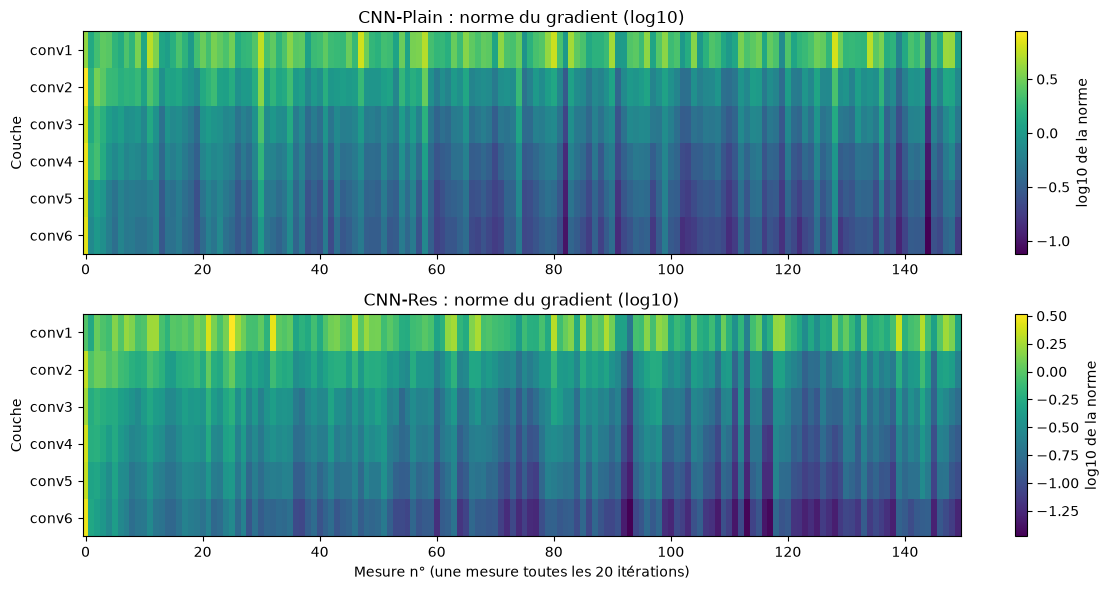

In [30]:
plt.figure(figsize=(12, 6))
for k, (nom, titre) in enumerate([("cnn_plain", "CNN-Plain"), ("cnn_res", "CNN-Res")]):
    g = pd.read_csv(C.RUNS_DIR / nom / "grad_norms.csv")
    tableau = g.pivot_table(index="layer_idx", columns="iter", values="grad_norm")   # lignes = couches, colonnes = itérations
    plt.subplot(2, 1, k + 1)
    plt.imshow(np.log10(tableau.values), aspect="auto", cmap="viridis")
    plt.colorbar(label="log10 de la norme")
    plt.yticks(range(6), ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6"])
    plt.ylabel("Couche")
    plt.title(titre + " : norme du gradient (log10)")
plt.xlabel("Mesure n° (une mesure toutes les 20 itérations)")
plt.tight_layout()
savefig("01_gradient_heatmap.png")
plt.show()

- Pour chaque couche, on prend la valeur médiane de la norme sur tout l'entraînement, et on trace une courbe par modèle.
- Le rapport conv1 / conv6 résume le tout : plus il est petit, plus le gradient s'affaiblit en remontant.

CNN-Plain : gradient conv1 / gradient conv6 = 7.348
CNN-Res : gradient conv1 / gradient conv6 = 7.042


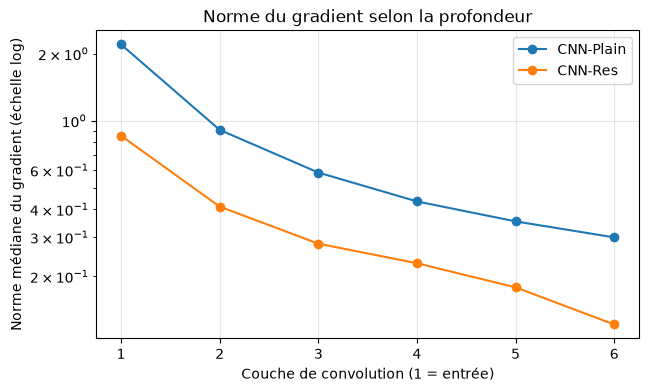

In [31]:
plt.figure(figsize=(7, 4))
for nom, titre in [("cnn_plain", "CNN-Plain"), ("cnn_res", "CNN-Res")]:
    g = pd.read_csv(C.RUNS_DIR / nom / "grad_norms.csv")
    mediane = g.groupby("layer_idx")["grad_norm"].median()     # une valeur par couche
    plt.plot(mediane.index, mediane.values, "o-", label=titre)
    print(titre, ": gradient conv1 / gradient conv6 =", round(mediane[1] / mediane[6], 3))
plt.yscale("log")
plt.xlabel("Couche de convolution (1 = entrée)")
plt.ylabel("Norme médiane du gradient (échelle log)")
plt.title("Norme du gradient selon la profondeur")
plt.legend()
plt.grid(alpha=0.3)
savefig("01_gradient_par_couche.png")
plt.show()

### Ce qu'on observe

On ne voit pas de disparition du gradient. Dans les deux modèles, c'est même la première couche qui reçoit le gradient le plus fort, et il diminue jusqu'à la sixième (rapport conv1 / conv6 d'environ 7 pour les deux).

Notre réseau n'a que 6 couches, et chaque convolution est suivie d'une BatchNorm, qui garde les valeurs à une échelle stable. Le cours cite trois moyens contre ce problème : la ReLU, la BatchNorm et les connexions résiduelles. Ici, les deux premiers suffisent.

Il faut aussi lire la figure avec prudence : conv1 a seulement 864 poids alors que conv6 en a 147 456, et la norme dépend aussi du nombre de poids.

L'intérêt des connexions résiduelles ne se voit donc pas sur le gradient à cette profondeur. On le voit plutôt sur la vitesse d'apprentissage, puisque CNN-Res est meilleur dès les premières époques. Le « + 1 » devient vraiment utile sur des réseaux de plusieurs dizaines de couches, là où apparaît la dégradation.

## 1.6 Évaluation sur le test et tableau comparatif

Chaque modèle final est évalué une seule fois sur le test, avec les poids qui avaient le meilleur F1 de validation.

- Pour chaque modèle : on recharge les meilleurs poids, on prédit le test et on calcule l'accuracy, le F1 macro, le rappel par classe et la matrice de confusion.
- Les prédictions sont gardées dans `results/preds/` pour l'analyse d'erreurs de la partie 6.
- On ajoute une ligne par modèle dans `summary.csv`.
- Dans une matrice de confusion, chaque ligne est une vraie classe ; la case sur la diagonale donne le rappel de cette classe.

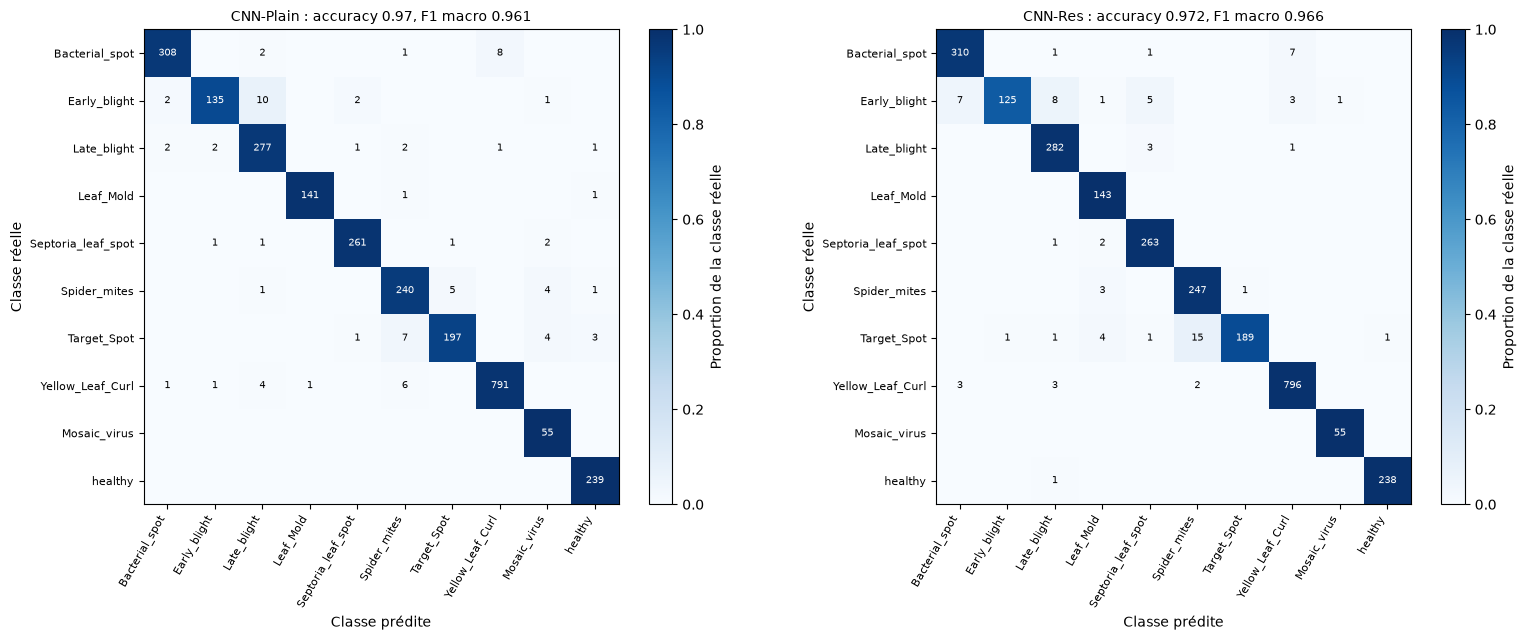

In [32]:
(C.RESULTS / "preds").mkdir(exist_ok=True)
rapports = {}
for nom, titre, model, h in [("cnn_plain", "CNN-Plain", plain, h_plain), ("cnn_res", "CNN-Res", res, h_res)]:
    model = load_best(model, nom)                              # meilleurs poids (validation)
    y_vrai, y_pred, proba = predict(model, loaders["test"])
    r = clf_report(y_vrai, y_pred, NOMS)
    rapports[titre] = r

    predictions = pd.DataFrame({"path": loaders["test"].dataset.df["path"], "y_true": y_vrai,
                                "y_pred": y_pred, "msp": proba.max(axis=1)})
    predictions.to_csv(C.RESULTS / "preds" / (nom + "_test.csv"), index=False)

    upsert_summary({"experiment": "P1_" + titre, "partie": 1, "modele": titre, "resolution": 128,
                    "hyperparametres": "Adam lr=0.001, batch 64, " + str(EPOCHS) + " époques",
                    "params": count_params(model)[0], "taille_mo": round(model_size_mb(model), 2),
                    "temps_entrainement_s": round(h["train_time_s"].iloc[-1], 1), "val_f1": round(h["val_f1"].max(), 4),
                    "test_acc": round(r["acc"], 4), "test_f1_macro": round(r["f1_macro"], 4), "run": nom})

plt.figure(figsize=(16, 6.5))
for k, titre in enumerate(["CNN-Plain", "CNN-Res"]):
    r = rapports[titre]
    ax = plt.subplot(1, 2, k + 1)
    plot_confusion(r["cm"], NOMS, titre + " : accuracy " + str(round(r["acc"], 3)) + ", F1 macro " + str(round(r["f1_macro"], 3)), ax=ax)
plt.tight_layout()
savefig("01_matrices_confusion.png")
plt.show()

- Rappel par classe des deux modèles, pour voir quelles maladies sont mal reconnues.
- Tableau comparatif demandé : paramètres, taille en Mo, temps d'entraînement, accuracy, F1 macro.

In [33]:
print("Rappel par classe sur le test :")
print(pd.DataFrame({"CNN-Plain": rapports["CNN-Plain"]["recall"], "CNN-Res": rapports["CNN-Res"]["recall"]}).round(3))

tableau = pd.DataFrame({
    "CNN-Plain": {"paramètres": count_params(plain)[0], "taille (Mo)": round(model_size_mb(plain), 2),
                  "temps d'entraînement (s)": round(h_plain["train_time_s"].iloc[-1]),
                  "accuracy test": round(rapports["CNN-Plain"]["acc"], 4), "F1 macro test": round(rapports["CNN-Plain"]["f1_macro"], 4)},
    "CNN-Res": {"paramètres": count_params(res)[0], "taille (Mo)": round(model_size_mb(res), 2),
                "temps d'entraînement (s)": round(h_res["train_time_s"].iloc[-1]),
                "accuracy test": round(rapports["CNN-Res"]["acc"], 4), "F1 macro test": round(rapports["CNN-Res"]["f1_macro"], 4)},
})
tableau

Rappel par classe sur le test :
                    CNN-Plain  CNN-Res
Bacterial_spot          0.966    0.972
Early_blight            0.900    0.833
Late_blight             0.969    0.986
Leaf_Mold               0.986    1.000
Septoria_leaf_spot      0.981    0.989
Spider_mites            0.956    0.984
Target_Spot             0.929    0.892
Yellow_Leaf_Curl        0.984    0.990
Mosaic_virus            1.000    1.000
healthy                 1.000    0.996


,CNN-Plain,CNN-Res
paramètres,1.336458e+06,1.190922e+06
taille (Mo),5.360000e+00,4.790000e+00
temps d'entraînement (s),2.320000e+02,3.590000e+02
accuracy test,9.703000e-01,9.717000e-01
F1 macro test,9.612000e-01,9.660000e-01


### Ce qu'on observe

Avec un nombre de paramètres comparable (1,34 M et 1,19 M), les deux modèles font presque jeu égal sur le test : 0,972 d'accuracy et 0,966 de F1 macro pour CNN-Res, 0,970 et 0,961 pour CNN-Plain. CNN-Res fait un peu mieux, avec moins de paramètres et un fichier plus léger (4,79 Mo contre 5,36 Mo).

La vraie différence est dans la répartition des paramètres. CNN-Plain en met 78 % dans sa couche Dense (1 048 608 poids rien que pour relier le Flatten à 32 neurones), tandis que CNN-Res les met dans ses convolutions, grâce au GAP qui ne coûte rien (TP2, exercice 6).

CNN-Res met plus de temps à s'entraîner (359 s contre 232 s). Ses convolutions sont plus larges (64, 128, 256 filtres) et travaillent sur de grandes cartes, donc il fait plus de calculs malgré ses paramètres moins nombreux.

La classe la plus difficile pour les deux est Early_blight (rappel de 0,90 pour CNN-Plain et 0,83 pour CNN-Res). Elle est souvent confondue avec Late_blight et Bacterial_spot, qui montrent aussi des taches brunes. CNN-Res prend aussi 15 images de Target_Spot pour du Spider_mites. À l'inverse, la mosaïque, pourtant la classe la plus rare, est reconnue à 100 % : son aspect est très particulier, et la perte pondérée l'aide.